# Notebook 12 — Solusi Collapse: Fitur Return (Stasioner) + Threshold Tuning F1-Macro + Perbandingan Horizon 1 vs 5

**Konteks masalah (rangkuman dari notebook 09 & 11, JANGAN didiagnosis ulang dari nol):**

- Notebook 09 (data sintetis, diagnostik): kombinasi **class-weight (inverse-freq) +
  threshold tuning berbasis F1-macro di validation** adalah teknik paling efektif
  mengatasi collapse (recall_DOWN 0.11 -> 0.48, f1_macro naik 4x). Mencari threshold
  via F1 kelas mayoritas/argmax **memperkuat** bias, bukan memperbaiki.
- Notebook 11 (data riil proyek, diagnostik akar masalah): model produksi horizon-1
  (`07_LSTM_FinBERT_skripsi_scoped.ipynb` / `notebook07_common.py`) **collapse total**
  (selalu menebak 1 kelas), horizon-5 tidak collapse tapi **bias terbalik** (recall
  kelas minoritas rendah). Akar masalah **TERKONFIRMASI**: (1) split kronologis 70/15/15
  kebetulan membelah data ke 3 rezim pasar berbeda (val = satu-satunya periode bear),
  (2) fitur `Open/High/Low/Close` memakai **harga level mentah** (non-stasioner) —
  10-13.5% baris test punya nilai ter-scaling **di luar rentang [0,1]** karena harga
  terus mencetak rekor baru, (3) korelasi fitur-label **berbalik tanda** train->test,
  konsisten dengan (2).

**Solusi yang diuji notebook ini (disepakati dgn user sebelum implementasi):**

1. **Ganti representasi fitur OHLCV dari harga level ke RETURN harian (%)** —
   `ret_open/high/low/close/volume = pct_change()`. Return bersifat stasioner
   (rentang nilai relatif stabil lintas rezim bull/bear), jadi MinMaxScaler yang
   di-fit di train seharusnya jauh lebih jarang "kepentok" di luar [0,1] saat
   diterapkan ke val/test — ini menyasar akar masalah (2) & (3) di atas secara
   langsung, BUKAN sekadar menambah fitur turunan di atas harga level (yang
   menurut notebook 09 TIDAK otomatis membantu).
2. **Label "Direction Return"** — `label = 1` jika
   `(Close[t+H] - Close[t]) / Close[t] > 0`. Catatan jujur: secara matematis ini
   **identik** dengan `Close[t+H] > Close[t]` (skema lama) — diverifikasi eksplisit
   di Bagian 1b. Perbaikan nyata datang dari (1) representasi FITUR yang berubah,
   bukan dari rumus label itu sendiri.
3. **Class-weight (inverse-freq) + threshold tuning F1-macro di validation**
   (resep notebook 09) diterapkan ke seleksi model Random Search — BUKAN val-F1
   kelas positif + argmax seperti `run_notebook07_training()` produksi.
4. **Bandingkan horizon 1 vs horizon 5** — dilatih apple-to-apples (search space,
   window, seed sama), horizon dengan performa lebih baik (F1-macro test sebagai
   metrik utama) yang direkomendasikan.

**Data:** OHLCV + sentimen (early fusion, `sentiment_mean`) — sesuai permintaan
eksplisit, fokus utama pada Model B. Model A (OHLCV-return saja) tetap disertakan
sebagai pembanding/ablation (konsisten konvensi notebook 07/10), TIDAK jadi
deliverable utama.

**PENTING:** Notebook ini **BELUM dieksekusi** (sesuai keputusan user) — semua
training akan dijalankan terpisah oleh user. Random Search 20 iterasi x hingga 80
epoch x 4 kombinasi (horizon x varian) bisa memakan waktu signifikan di CPU;
disarankan pakai GPU (`torch.cuda.is_available()`) bila tersedia.

**Artefak yang disimpan** (terisolasi, TIDAK menimpa model produksi/skripsi resmi):
`data/artifacts/lstm_weights/notebook12_return_h{1,5}_model{A,B}.{pt,joblib,json}`,
plus `notebook12_return_best.*` untuk horizon+varian Model B yang terpilih.

## Bagian 1 — Data & Fitur Return (ganti dari harga level ke return harian)

Reuse `pipeline/feature_engineering/dataset_builder.py::load_joined()` (OHLCV +
sentimen harian, data riil proyek — BUKAN data sintetis seperti notebook 09).
Fitur baru dihitung LANGSUNG di notebook ini (bukan menambah fungsi ke
`dataset_builder.py` produksi — eksperimen ini terisolasi, konsisten pola
notebook 09/11 sebelumnya yang juga self-contained).

In [1]:
import json
import sys
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if (Path.cwd() / "notebooks").exists() is False else Path.cwd()
if (PROJECT_ROOT / "pipeline").exists() is False:
    PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT))

import logging

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

from pipeline.feature_engineering.dataset_builder import FEATURE_COLS, load_joined
from models.lstm.lstm_model import FlexibleLSTMClassifier
from models.lstm.notebook07_common import (
    build_optimizer,
    compute_class_weights,
    load_split_capped,
    sample_config,
)
from models.lstm.notebook07_trainer import SEARCH_SPACE, N_ITER, WINDOW

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(name)s: %(message)s")
logger = logging.getLogger("notebook12")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info("Device: %s", DEVICE)

ARTIFACT_DIR = str(PROJECT_ROOT / "data" / "artifacts" / "lstm_weights")
SEED = 42

2026-07-28 15:29:23,421 [INFO] notebook12: Device: cuda


In [2]:
def load_return_features() -> pd.DataFrame:
    '''OHLCV + sentimen (load_joined) dengan Open/High/Low/Close/Volume
    dikonversi ke RETURN harian (pct_change) -- fitur stasioner, bukan harga
    level mentah. Kolom "Close" (level, BUKAN return) tetap disimpan karena
    dibutuhkan `load_split_capped()` untuk menghitung label horizon-N.

    Baris pertama (NaN akibat pct_change) dibuang. `ret_volume` bisa jadi inf
    kalau ada hari Volume=0 (dikonfirmasi 1 baris di data ini, sama seperti
    catatan perbaikan notebook 03 2026-06-16) -- inf/-inf diganti NaN lalu
    dibuang, BUKAN diisi 0 (supaya tidak menyamarkan hari anomali sebagai
    "tidak ada perubahan").
    '''
    df = load_joined()  # Date, Open, High, Low, Close, Volume, sentiment_mean

    df["ret_open"] = df["Open"].pct_change()
    df["ret_high"] = df["High"].pct_change()
    df["ret_low"] = df["Low"].pct_change()
    df["ret_close"] = df["Close"].pct_change()
    df["ret_volume"] = df["Volume"].pct_change()

    ret_cols = ["ret_open", "ret_high", "ret_low", "ret_close", "ret_volume"]
    n_inf = int(np.isinf(df[ret_cols].values).sum())
    if n_inf:
        logger.info("Mengganti %d nilai inf (Volume=0 pada suatu hari) dengan NaN", n_inf)
        df[ret_cols] = df[ret_cols].replace([np.inf, -np.inf], np.nan)

    n_before = len(df)
    df = df.dropna(subset=ret_cols).reset_index(drop=True)
    logger.info("load_return_features(): %d baris (%d dibuang krn NaN pct_change/inf)", len(df), n_before - len(df))

    return df[["Date", "ret_open", "ret_high", "ret_low", "ret_close", "ret_volume", "sentiment_mean", "Close"]]


RETURN_FEATURE_COLS_A = ["ret_open", "ret_high", "ret_low", "ret_close", "ret_volume"]
RETURN_FEATURE_COLS_B = RETURN_FEATURE_COLS_A + ["sentiment_mean"]

df_ret = load_return_features()
print(df_ret.shape)
df_ret.describe().T

2026-07-28 15:29:23,459 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,460 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:29:23,465 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,470 [INFO] notebook12: Mengganti 1 nilai inf (Volume=0 pada suatu hari) dengan NaN
2026-07-28 15:29:23,473 [INFO] notebook12: load_return_features(): 1526 baris (2 dibuang krn NaN pct_change/inf)


(1526, 8)


,count,mean,min,25%,50%,75%,max,std
Date,1526,2021-02-03 12:38:41.363040,2018-01-03 00:00:00,2019-07-26 18:00:00,2021-02-08 12:00:00,2022-08-15 18:00:00,2024-03-04 00:00:00,NaN
ret_open,1526.0,0.000481,-0.06892,-0.004273,0.001131,0.006306,0.0622,0.010952
ret_high,1526.0,0.000469,-0.062079,-0.003684,0.000964,0.005312,0.064753,0.009965
ret_low,1526.0,0.000484,-0.084352,-0.004583,0.001156,0.00636,0.069612,0.011241
ret_close,1526.0,0.000501,-0.119841,-0.004988,0.00082,0.007002,0.093828,0.012984
ret_volume,1526.0,0.014618,-1.0,-0.069084,-0.005559,0.079005,1.270527,0.183533
sentiment_mean,1526.0,-0.053929,-1.0,-0.272727,0.0,0.142857,1.0,0.345535
Close,1526.0,3629.486009,2237.399902,2900.664978,3740.0,4273.724976,5137.080078,716.918043


## Bagian 1b — Verifikasi Definisi Label & Bukti Stasioneritas

1. Buktikan `label = (Close[t+H] > Close[t])` (skema lama, dipakai
   `load_split_capped()`) **identik** secara matematis dengan
   `label = ((Close[t+H]-Close[t])/Close[t] > 0)` ("Direction Return") — supaya
   jujur ke user bahwa perbaikan bukan dari rumus label, tapi dari representasi
   fitur.
2. Bandingkan statistik `Close` (level) vs `ret_close` (return) PER TAHUN —
   kalau level terus naik (mean/rentang bergeser tiap tahun) sementara return
   relatif stabil di sekitar 0, itu bukti visual non-stasioneritas yang
   dilaporkan notebook 11.

In [3]:
_df_check = load_joined().copy()
_h = 1
_close = _df_check["Close"]
_label_close_gt = (_close.shift(-_h) > _close)
_fwd_return = (_close.shift(-_h) - _close) / _close
_label_return_gt = (_fwd_return > 0)

_mask = _label_close_gt.notna()
n_match = (_label_close_gt[_mask] == _label_return_gt[_mask]).sum()
n_total = int(_mask.sum())
print(f"Direction Close == Direction Return pada {n_match}/{n_total} baris "
      f"({'IDENTIK' if n_match == n_total else 'ADA PERBEDAAN -- cek ulang!'})")

_df_check["year"] = _df_check["Date"].dt.year
_df_check["ret_close"] = _close.pct_change()
yearly = _df_check.groupby("year").agg(
    close_mean=("Close", "mean"),
    close_min=("Close", "min"),
    close_max=("Close", "max"),
    ret_close_mean=("ret_close", "mean"),
    ret_close_std=("ret_close", "std"),
)
yearly

2026-07-28 15:29:23,516 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,517 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:29:23,521 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)


Direction Close == Direction Return pada 1528/1528 baris (IDENTIK)


,close_mean,close_min,close_max,ret_close_mean,ret_close_std
year,,,,,
2018,2744.062181,2351.100098,2930.750000,-0.000240,0.011020
2019,2913.221686,2447.889893,3240.020020,0.001055,0.007899
2020,3217.701364,2237.399902,3735.360107,0.000819,0.021844
2021,4274.363520,3700.649902,4793.060059,0.001013,0.008244
2022,4098.514748,3577.030029,4796.560059,-0.000745,0.015228
2023,4287.825204,3808.100098,4783.350098,0.000923,0.008190
2024,4916.315827,4688.680176,5137.080078,0.001724,0.007192


## Bagian 1c — Kuantifikasi Perbaikan: % Baris Ter-scaling di Luar [0,1]

Reproduksi cepat temuan notebook 11 (10-13.5% baris test di luar rentang [0,1]
untuk fitur harga level) sebagai angka pembanding SEGAR (bukan kutip lama), lalu
hitung angka yang sama untuk fitur return. Split & capping pakai konvensi PERSIS
sama dengan model skripsi resmi (`capping_cols=["Volume","sentiment_mean"]`,
horizon=1) supaya perbandingan adil.

In [4]:
def pct_out_of_range(feature_cols: list[str], load_data_fn, capping_cols: list[str], horizon: int = 1) -> dict:
    df_train, df_val, df_test, _, _ = load_split_capped(load_data_fn, capping_cols, horizon)
    scaler = MinMaxScaler()
    scaler.fit(df_train[feature_cols].values.astype(np.float64))
    val_feat = scaler.transform(df_val[feature_cols].values.astype(np.float64))
    test_feat = scaler.transform(df_test[feature_cols].values.astype(np.float64))
    return {
        "val_pct": float(((val_feat < 0) | (val_feat > 1)).any(axis=1).mean() * 100),
        "test_pct": float(((test_feat < 0) | (test_feat > 1)).any(axis=1).mean() * 100),
    }


old_price_level = pct_out_of_range(FEATURE_COLS, load_joined, ["Volume", "sentiment_mean"], horizon=1)
new_return = pct_out_of_range(RETURN_FEATURE_COLS_B, load_return_features, RETURN_FEATURE_COLS_B, horizon=1)

print("Fitur harga level (skema LAMA, produksi)  :", old_price_level)
print("Fitur return      (skema BARU, notebook ini):", new_return)

2026-07-28 15:29:23,582 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,583 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:29:23,587 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,607 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,609 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:29:23,612 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,616 [INFO] notebook12: Mengganti 1 nilai inf (Volume=0 pada suatu hari) dengan NaN
2026-07-28 15:29:23,619 [INFO] notebook12: load_return_features(): 1526 baris (2 dibuang krn NaN pct_change/inf)


Fitur harga level (skema LAMA, produksi)  : {'val_pct': 0.0, 'test_pct': 13.478260869565217}
Fitur return      (skema BARU, notebook ini): {'val_pct': 0.0, 'test_pct': 0.0}


## Bagian 2 — Fungsi Training: Random Search + Class-Weight + Threshold Tuning F1-Macro

`sweep_best_threshold()` — cari threshold probabilitas kelas "up" yang
memaksimalkan **F1-macro** di validation (perbaikan langsung atas bug yang
didiagnosis notebook 09: threshold via F1 kelas mayoritas/argmax memperkuat
bias).

`run_random_search_return()` — reuse `sample_config`/`build_optimizer`/
`compute_class_weights`/`load_split_capped` dari `notebook07_common.py` (SATU-
SATUNYA salinan logic split/capping/sampling — tidak reinvent), TAPI loop
training & kriteria seleksi model terbaik DITULIS ULANG di sini (bukan
`run_notebook07_training()`) karena fungsi produksi itu menyeleksi/mengevaluasi
pakai val-F1 kelas positif + argmax, sedangkan notebook ini butuh macro-F1 +
threshold tuning eksplisit. Modul produksi `notebook07_common.py` TIDAK diubah
sama sekali — training/inference API tetap berjalan seperti sebelumnya.

Capping outlier IQR (fit-train-only) diterapkan ke SEMUA kolom fitur return
(beda dari skripsi lama yang hanya meng-capping Volume+sentimen, karena OHLC
level sengaja tidak di-capping) -- di representasi return, kelima kolom
sama-sama rentan outlier ekstrem (hari crash/rally), jadi capping diterapkan
merata.

In [5]:
def _make_windows(features: np.ndarray, labels: np.ndarray, window: int) -> tuple[np.ndarray, np.ndarray]:
    n = len(features)
    if n < window:
        return (
            np.empty((0, window, features.shape[1]), dtype=np.float32),
            np.empty((0,), dtype=np.int64),
        )
    num_samples = n - window + 1
    X = np.stack([features[i : i + window] for i in range(num_samples)]).astype(np.float32)
    y = labels[window - 1 : window - 1 + num_samples].astype(np.int64)
    return X, y


def sweep_best_threshold(y_true: np.ndarray, probs_up: np.ndarray, n_steps: int = 197) -> tuple[float, float]:
    best_t, best_score = 0.5, -1.0
    for t in np.linspace(0.01, 0.99, n_steps):
        preds = (probs_up >= t).astype(int)
        score = f1_score(y_true, preds, average="macro", zero_division=0)
        if score > best_score:
            best_score, best_t = score, float(t)
    return best_t, float(best_score)

In [6]:
def run_random_search_return(
    *,
    label: str,
    feature_cols: list[str],
    load_data_fn,
    capping_cols: list[str],
    horizon: int,
    window: int = WINDOW,
    search_space: dict = SEARCH_SPACE,
    n_iter: int = N_ITER,
    seed: int = SEED,
    device: torch.device = DEVICE,
) -> dict:
    df_train, df_val, df_test, capping_bounds, n_capped = load_split_capped(
        load_data_fn, capping_cols, horizon
    )

    scaler = MinMaxScaler()
    train_feat = scaler.fit_transform(df_train[feature_cols].values.astype(np.float64))
    val_feat = scaler.transform(df_val[feature_cols].values.astype(np.float64))
    test_feat = scaler.transform(df_test[feature_cols].values.astype(np.float64))

    out_of_range_val_pct = float(((val_feat < 0) | (val_feat > 1)).any(axis=1).mean() * 100)
    out_of_range_test_pct = float(((test_feat < 0) | (test_feat > 1)).any(axis=1).mean() * 100)

    X_train, y_train = _make_windows(train_feat, df_train["label"].values, window)
    X_val, y_val = _make_windows(val_feat, df_val["label"].values, window)
    X_test, y_test = _make_windows(test_feat, df_test["label"].values, window)

    rng = np.random.default_rng(seed)
    best = {"val_macro_f1": -1.0, "config": None, "state_dict": None, "threshold": 0.5}

    train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
    X_val_t = torch.from_numpy(X_val).to(device)

    print(f"=== {label} | horizon={horizon} | train={len(X_train)} val={len(X_val)} test={len(X_test)} "
          f"| out-of-range scaling val={out_of_range_val_pct:.1f}% test={out_of_range_test_pct:.1f}% ===")

    for i in range(n_iter):
        config = sample_config(rng, search_space)
        torch.manual_seed(seed + i)
        model = FlexibleLSTMClassifier(
            input_size=len(feature_cols),
            hidden_size=config["hidden_size"],
            num_layers=config["num_layers"],
            dropout=config["dropout"],
            activation=config["activation"],
            num_classes=2,
        ).to(device)

        optimizer = build_optimizer(config["optimizer"], model.parameters(), config["lr"])
        class_weights = compute_class_weights(y_train, device)
        criterion = nn.CrossEntropyLoss(weight=class_weights)
        train_loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True)

        for _epoch in range(config["epochs"]):
            model.train()
            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad()
                loss = criterion(model(xb), yb)
                loss.backward()
                optimizer.step()

        model.eval()
        with torch.no_grad():
            val_probs = torch.softmax(model(X_val_t), dim=1)[:, 1].cpu().numpy()
        best_t, val_macro_f1 = sweep_best_threshold(y_val, val_probs)

        is_new_best = val_macro_f1 > best["val_macro_f1"]
        print(f"  iter {i+1:2d}/{n_iter} | hidden={config['hidden_size']:3d} layers={config['num_layers']} "
              f"opt={config['optimizer']:7s} act={config['activation']:7s} epochs={config['epochs']:2d} | "
              f"val_macro_f1={val_macro_f1:.4f} best_t={best_t:.2f}"
              f"{'  <- new best' if is_new_best else ''}")

        if is_new_best:
            best = {
                "val_macro_f1": val_macro_f1,
                "config": config,
                "state_dict": deepcopy({k: v.detach().cpu().clone() for k, v in model.state_dict().items()}),
                "threshold": best_t,
            }

    assert best["state_dict"] is not None, "Random Search tidak menghasilkan model terbaik"

    best_model = FlexibleLSTMClassifier(
        input_size=len(feature_cols),
        hidden_size=best["config"]["hidden_size"],
        num_layers=best["config"]["num_layers"],
        dropout=best["config"]["dropout"],
        activation=best["config"]["activation"],
        num_classes=2,
    ).to(device)
    best_model.load_state_dict(best["state_dict"])
    best_model.eval()

    with torch.no_grad():
        test_probs = torch.softmax(best_model(torch.from_numpy(X_test).to(device)), dim=1)[:, 1].cpu().numpy()
    y_pred = (test_probs >= best["threshold"]).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    metrics = {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall": float(recall_score(y_test, y_pred, zero_division=0)),
        "f1": float(f1_score(y_test, y_pred, zero_division=0)),
        "f1_macro": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
        "recall_down": float(recall_score(y_test, y_pred, pos_label=0, zero_division=0)),
        "recall_up": float(recall_score(y_test, y_pred, pos_label=1, zero_division=0)),
    }

    print(f"  >> TEST  acc={metrics['accuracy']:.3f} prec={metrics['precision']:.3f} "
          f"recall={metrics['recall']:.3f} f1={metrics['f1']:.3f} f1_macro={metrics['f1_macro']:.3f} "
          f"| recall_down={metrics['recall_down']:.3f} recall_up={metrics['recall_up']:.3f}")

    return {
        "label": label,
        "horizon": horizon,
        "feature_cols": feature_cols,
        "window": window,
        "best_config": best["config"],
        "best_threshold": best["threshold"],
        "best_val_macro_f1": best["val_macro_f1"],
        "metrics": metrics,
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
        "test_probs": test_probs,
        "y_test": y_test,
        "y_train": y_train,
        "model_state_dict": best["state_dict"],
        "scaler": scaler,
        "out_of_range_val_pct": out_of_range_val_pct,
        "out_of_range_test_pct": out_of_range_test_pct,
        "split_sizes": {
            "train_rows": len(df_train), "val_rows": len(df_val), "test_rows": len(df_test),
            "train_samples": len(X_train), "val_samples": len(X_val), "test_samples": len(X_test),
        },
    }

## Bagian 3 — Baseline Sederhana (Majority & Persistence)

Sesuai prinsip notebook 09: model TIDAK dianggap berhasil belajar kalau tidak
mengungguli baseline trivial ini. Dihitung per horizon (baseline sama untuk
Model A & B karena label & split sama, hanya fitur yang beda).

In [7]:
def simple_baselines(y_train: np.ndarray, y_test: np.ndarray) -> dict:
    majority_class = int(pd.Series(y_train).mode().iloc[0])
    majority_pred = np.full_like(y_test, majority_class)

    persistence_pred = np.empty_like(y_test)
    persistence_pred[0] = majority_class  # tidak ada label sebelumnya di awal test
    persistence_pred[1:] = y_test[:-1]

    def _metrics(preds):
        return {
            "accuracy": float(accuracy_score(y_test, preds)),
            "precision": float(precision_score(y_test, preds, zero_division=0)),
            "recall": float(recall_score(y_test, preds, zero_division=0)),
            "f1": float(f1_score(y_test, preds, zero_division=0)),
            "f1_macro": float(f1_score(y_test, preds, average="macro", zero_division=0)),
        }

    return {"majority": _metrics(majority_pred), "persistence": _metrics(persistence_pred)}

## Bagian 4 — Jalankan Eksperimen: Horizon 1 vs Horizon 5, Model A vs Model B

4 kombinasi, search space/window/seed identik (apples-to-apples, sesuai prinsip
anti p-hacking yang sudah dipegang project ini di notebook 03/06/10). Model B
(OHLCV+sentimen) adalah deliverable utama; Model A (OHLCV saja) pembanding.

**Perhatian runtime:** tiap `run_random_search_return()` = `N_ITER` (20) x
`config["epochs"]` (s.d. 80) forward-backward pass penuh. 4 kombinasi bisa
memakan waktu cukup lama di CPU.

In [8]:
result_h1_a = run_random_search_return(
    label="Model A (OHLCV-return) h1",
    feature_cols=RETURN_FEATURE_COLS_A,
    load_data_fn=load_return_features,
    capping_cols=RETURN_FEATURE_COLS_A,
    horizon=1,
)

2026-07-28 15:29:23,683 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,684 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:29:23,689 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:29:23,693 [INFO] notebook12: Mengganti 1 nilai inf (Volume=0 pada suatu hari) dengan NaN
2026-07-28 15:29:23,695 [INFO] notebook12: load_return_features(): 1526 baris (2 dibuang krn NaN pct_change/inf)


=== Model A (OHLCV-return) h1 | horizon=1 | train=1058 val=219 test=221 | out-of-range scaling val=0.0% test=0.0% ===
  iter  1/20 | hidden= 64 layers=1 opt=adam    act=sigmoid epochs=30 | val_macro_f1=0.3559 best_t=0.51  <- new best
  iter  2/20 | hidden= 64 layers=2 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.3559 best_t=0.52
  iter  3/20 | hidden= 16 layers=2 opt=rmsprop act=sigmoid epochs=50 | val_macro_f1=0.3559 best_t=0.51
  iter  4/20 | hidden= 16 layers=2 opt=sgd     act=sigmoid epochs=30 | val_macro_f1=0.3559 best_t=0.59
  iter  5/20 | hidden= 64 layers=1 opt=rmsprop act=sigmoid epochs=80 | val_macro_f1=0.4818 best_t=0.50  <- new best
  iter  6/20 | hidden= 32 layers=1 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.5289 best_t=0.50  <- new best
  iter  7/20 | hidden= 32 layers=2 opt=sgd     act=tanh    epochs=30 | val_macro_f1=0.3559 best_t=0.51
  iter  8/20 | hidden= 32 layers=1 opt=adam    act=relu    epochs=50 | val_macro_f1=0.4925 best_t=0.49
  iter  9/20 | hidd

In [9]:
result_h1_b = run_random_search_return(
    label="Model B (OHLCV+sentimen-return) h1",
    feature_cols=RETURN_FEATURE_COLS_B,
    load_data_fn=load_return_features,
    capping_cols=RETURN_FEATURE_COLS_B,
    horizon=1,
)

2026-07-28 15:31:20,994 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:31:20,996 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:31:21,001 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:31:21,006 [INFO] notebook12: Mengganti 1 nilai inf (Volume=0 pada suatu hari) dengan NaN
2026-07-28 15:31:21,009 [INFO] notebook12: load_return_features(): 1526 baris (2 dibuang krn NaN pct_change/inf)


=== Model B (OHLCV+sentimen-return) h1 | horizon=1 | train=1058 val=219 test=221 | out-of-range scaling val=0.0% test=0.0% ===
  iter  1/20 | hidden= 64 layers=1 opt=adam    act=sigmoid epochs=30 | val_macro_f1=0.3559 best_t=0.51  <- new best
  iter  2/20 | hidden= 64 layers=2 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.3559 best_t=0.53
  iter  3/20 | hidden= 16 layers=2 opt=rmsprop act=sigmoid epochs=50 | val_macro_f1=0.3559 best_t=0.51
  iter  4/20 | hidden= 16 layers=2 opt=sgd     act=sigmoid epochs=30 | val_macro_f1=0.3559 best_t=0.51
  iter  5/20 | hidden= 64 layers=1 opt=rmsprop act=sigmoid epochs=80 | val_macro_f1=0.4952 best_t=0.51  <- new best
  iter  6/20 | hidden= 32 layers=1 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.5096 best_t=0.50  <- new best
  iter  7/20 | hidden= 32 layers=2 opt=sgd     act=tanh    epochs=30 | val_macro_f1=0.3559 best_t=0.51
  iter  8/20 | hidden= 32 layers=1 opt=adam    act=relu    epochs=50 | val_macro_f1=0.4609 best_t=0.51
  iter  9/

In [10]:
result_h5_a = run_random_search_return(
    label="Model A (OHLCV-return) h5",
    feature_cols=RETURN_FEATURE_COLS_A,
    load_data_fn=load_return_features,
    capping_cols=RETURN_FEATURE_COLS_A,
    horizon=5,
)

2026-07-28 15:33:15,078 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:33:15,080 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:33:15,083 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:33:15,087 [INFO] notebook12: Mengganti 1 nilai inf (Volume=0 pada suatu hari) dengan NaN
2026-07-28 15:33:15,089 [INFO] notebook12: load_return_features(): 1526 baris (2 dibuang krn NaN pct_change/inf)


=== Model A (OHLCV-return) h5 | horizon=5 | train=1055 val=219 test=220 | out-of-range scaling val=0.0% test=0.0% ===
  iter  1/20 | hidden= 64 layers=1 opt=adam    act=sigmoid epochs=30 | val_macro_f1=0.3423 best_t=0.01  <- new best
  iter  2/20 | hidden= 64 layers=2 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.3423 best_t=0.01
  iter  3/20 | hidden= 16 layers=2 opt=rmsprop act=sigmoid epochs=50 | val_macro_f1=0.3423 best_t=0.01
  iter  4/20 | hidden= 16 layers=2 opt=sgd     act=sigmoid epochs=30 | val_macro_f1=0.3423 best_t=0.01
  iter  5/20 | hidden= 64 layers=1 opt=rmsprop act=sigmoid epochs=80 | val_macro_f1=0.3423 best_t=0.01
  iter  6/20 | hidden= 32 layers=1 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.4835 best_t=0.51  <- new best
  iter  7/20 | hidden= 32 layers=2 opt=sgd     act=tanh    epochs=30 | val_macro_f1=0.4620 best_t=0.50
  iter  8/20 | hidden= 32 layers=1 opt=adam    act=relu    epochs=50 | val_macro_f1=0.4868 best_t=0.49  <- new best
  iter  9/20 | hidd

In [11]:
result_h5_b = run_random_search_return(
    label="Model B (OHLCV+sentimen-return) h5",
    feature_cols=RETURN_FEATURE_COLS_B,
    load_data_fn=load_return_features,
    capping_cols=RETURN_FEATURE_COLS_B,
    horizon=5,
)

2026-07-28 15:35:06,333 [INFO] pipeline.feature_engineering.dataset_builder: Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:35:06,335 [INFO] pipeline.feature_engineering.dataset_builder: Sentiment loaded: 3507 rows (2008-01-02 – 2024-03-04)
2026-07-28 15:35:06,341 [INFO] pipeline.feature_engineering.dataset_builder: Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
2026-07-28 15:35:06,350 [INFO] notebook12: Mengganti 1 nilai inf (Volume=0 pada suatu hari) dengan NaN
2026-07-28 15:35:06,356 [INFO] notebook12: load_return_features(): 1526 baris (2 dibuang krn NaN pct_change/inf)


=== Model B (OHLCV+sentimen-return) h5 | horizon=5 | train=1055 val=219 test=220 | out-of-range scaling val=0.0% test=0.0% ===
  iter  1/20 | hidden= 64 layers=1 opt=adam    act=sigmoid epochs=30 | val_macro_f1=0.3423 best_t=0.01  <- new best
  iter  2/20 | hidden= 64 layers=2 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.3423 best_t=0.01
  iter  3/20 | hidden= 16 layers=2 opt=rmsprop act=sigmoid epochs=50 | val_macro_f1=0.3423 best_t=0.01
  iter  4/20 | hidden= 16 layers=2 opt=sgd     act=sigmoid epochs=30 | val_macro_f1=0.3423 best_t=0.01
  iter  5/20 | hidden= 64 layers=1 opt=rmsprop act=sigmoid epochs=80 | val_macro_f1=0.3423 best_t=0.01
  iter  6/20 | hidden= 32 layers=1 opt=rmsprop act=relu    epochs=80 | val_macro_f1=0.5271 best_t=0.50  <- new best
  iter  7/20 | hidden= 32 layers=2 opt=sgd     act=tanh    epochs=30 | val_macro_f1=0.3423 best_t=0.01
  iter  8/20 | hidden= 32 layers=1 opt=adam    act=relu    epochs=50 | val_macro_f1=0.5001 best_t=0.51
  iter  9/20 | hidden= 

In [12]:
baseline_h1 = simple_baselines(result_h1_b["y_train"], result_h1_b["y_test"])
baseline_h5 = simple_baselines(result_h5_b["y_train"], result_h5_b["y_test"])
print("Baseline horizon 1:", json.dumps(baseline_h1, indent=2))
print("Baseline horizon 5:", json.dumps(baseline_h5, indent=2))

Baseline horizon 1: {
  "majority": {
    "accuracy": 0.5610859728506787,
    "precision": 0.5610859728506787,
    "recall": 1.0,
    "f1": 0.7188405797101449,
    "f1_macro": 0.35942028985507246
  },
  "persistence": {
    "accuracy": 0.48868778280542985,
    "precision": 0.544,
    "recall": 0.5483870967741935,
    "f1": 0.5461847389558233,
    "f1_macro": 0.48034625548827437
  }
}
Baseline horizon 5: {
  "majority": {
    "accuracy": 0.6454545454545455,
    "precision": 0.6454545454545455,
    "recall": 1.0,
    "f1": 0.7845303867403315,
    "f1_macro": 0.39226519337016574
  },
  "persistence": {
    "accuracy": 0.8090909090909091,
    "precision": 0.852112676056338,
    "recall": 0.852112676056338,
    "f1": 0.852112676056338,
    "f1_macro": 0.7914409534127844
  }
}


## Bagian 5 — Diagnosa Collapse (Histogram Probabilitas + Recall per Kelas)

Reuse diagnostik notebook 09: std probabilitas sigmoid/softmax yang sangat
kecil (~0.05-0.06) = tanda collapse. Dicek untuk keempat kombinasi — dilaporkan
APA ADANYA meski hasilnya masih menunjukkan collapse/bias.

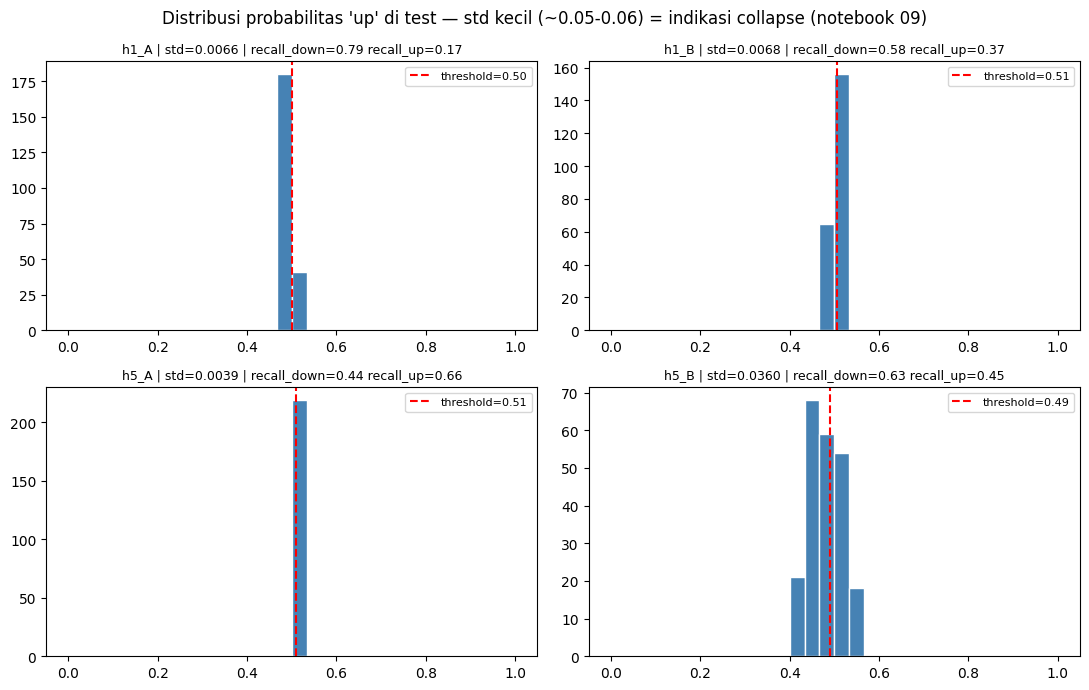

In [13]:
all_results = {
    "h1_A": result_h1_a, "h1_B": result_h1_b,
    "h5_A": result_h5_a, "h5_B": result_h5_b,
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, res) in zip(axes.ravel(), all_results.items()):
    probs = res["test_probs"]
    ax.hist(probs, bins=30, range=(0, 1), color="steelblue", edgecolor="white")
    ax.axvline(res["best_threshold"], color="red", linestyle="--", label=f"threshold={res['best_threshold']:.2f}")
    ax.set_title(f"{name} | std={probs.std():.4f} | recall_down={res['metrics']['recall_down']:.2f} "
                 f"recall_up={res['metrics']['recall_up']:.2f}", fontsize=9)
    ax.legend(fontsize=8)
fig.suptitle("Distribusi probabilitas 'up' di test — std kecil (~0.05-0.06) = indikasi collapse (notebook 09)")
fig.tight_layout()
plt.show()

## Bagian 6 — Tabel Perbandingan Lengkap

Baseline lama (Random Search skripsi resmi, fitur harga level) dibaca LANGSUNG
dari metadata artefak tersimpan (`*_skripsi[_h5]_metadata.json`) — bukan angka
hardcode, supaya selalu sinkron kalau model produksi dilatih ulang. Semua baris
ditampilkan apa adanya, termasuk kalau solusi baru ternyata TIDAK mengungguli
baseline di metrik tertentu.

In [14]:
def load_metadata(filename: str) -> dict:
    path = Path(ARTIFACT_DIR) / filename
    if not path.exists():
        return {}
    return json.loads(path.read_text(encoding="utf-8"))


old_meta = {
    "Baseline lama h1 - Model A (harga level)": load_metadata("lstm_baseline_skripsi_metadata.json"),
    "Baseline lama h1 - Model B (harga level)": load_metadata("finbert_lstm_skripsi_metadata.json"),
    "Baseline lama h5 - Model A (harga level)": load_metadata("lstm_baseline_skripsi_h5_metadata.json"),
    "Baseline lama h5 - Model B (harga level)": load_metadata("finbert_lstm_skripsi_h5_metadata.json"),
}

rows = []
for name, meta in old_meta.items():
    if not meta:
        continue
    m = meta["metrics"]
    rows.append({
        "Model": name, "Accuracy": m["accuracy"], "Precision": m["precision"],
        "Recall": m["recall"], "F1": m["f1"], "F1-macro": None,
        "Recall_down": None, "Recall_up": None,
    })

for name, base in [("Baseline sederhana h1 - Majority", baseline_h1["majority"]),
                    ("Baseline sederhana h1 - Persistence", baseline_h1["persistence"]),
                    ("Baseline sederhana h5 - Majority", baseline_h5["majority"]),
                    ("Baseline sederhana h5 - Persistence", baseline_h5["persistence"])]:
    rows.append({
        "Model": name, "Accuracy": base["accuracy"], "Precision": base["precision"],
        "Recall": base["recall"], "F1": base["f1"], "F1-macro": base["f1_macro"],
        "Recall_down": None, "Recall_up": None,
    })

for name, res in [("SOLUSI BARU h1 - Model A (return)", result_h1_a),
                   ("SOLUSI BARU h1 - Model B (return)", result_h1_b),
                   ("SOLUSI BARU h5 - Model A (return)", result_h5_a),
                   ("SOLUSI BARU h5 - Model B (return)", result_h5_b)]:
    m = res["metrics"]
    rows.append({
        "Model": name, "Accuracy": m["accuracy"], "Precision": m["precision"],
        "Recall": m["recall"], "F1": m["f1"], "F1-macro": m["f1_macro"],
        "Recall_down": m["recall_down"], "Recall_up": m["recall_up"],
    })

comparison_df = pd.DataFrame(rows)
pd.set_option("display.width", 140)
comparison_df

,Model,Accuracy,Precision,Recall,F1,F1-macro,Recall_down,Recall_up
0,Baseline lama h1 - Model A (harga level),0.450331,0.000000,0.000000,0.000000,NaN,NaN,NaN
1,Baseline lama h1 - Model B (harga level),0.451178,0.000000,0.000000,0.000000,NaN,NaN,NaN
2,Baseline lama h5 - Model A (harga level),0.383929,0.681818,0.102740,0.178571,NaN,NaN,NaN
3,Baseline lama h5 - Model B (harga level),0.404545,0.772727,0.118881,0.206061,NaN,NaN,NaN
4,Baseline sederhana h1 - Majority,0.561086,0.561086,1.000000,0.718841,0.359420,NaN,NaN
5,Baseline sederhana h1 - Persistence,0.488688,0.544000,0.548387,0.546185,0.480346,NaN,NaN
6,Baseline sederhana h5 - Majority,0.645455,0.645455,1.000000,0.784530,0.392265,NaN,NaN
7,Baseline sederhana h5 - Persistence,0.809091,0.852113,0.852113,0.852113,0.791441,NaN,NaN
8,SOLUSI BARU h1 - Model A (return),0.443439,0.512195,0.169355,0.254545,0.405251,0.793814,0.169355
9,SOLUSI BARU h1 - Model B (return),0.461538,0.528736,0.370968,0.436019,0.460434,0.577320,0.370968


## Bagian 7 — Pilih Horizon Terbaik (Model B) & Simpan Artefak

Keputusan horizon HANYA dibandingkan antar **Model B** (OHLCV+sentimen, sesuai
instruksi eksplisit user "gunakan data OHLCV+sentimen") memakai **F1-macro test**
sebagai kriteria utama (bukan accuracy — accuracy menyesatkan kalau data
imbalance, konsisten alasan notebook 09 kenapa F1-macro dipakai utk threshold
tuning). Precision/Recall/Accuracy tetap dilaporkan berdampingan, apa adanya.

Semua 4 kombinasi TETAP disimpan (transparansi/reproducibility), horizon
terpilih Model B disalin sekali lagi ke nama file "_best" supaya mudah dipakai
lanjutan (mis. dibuatkan endpoint/predict) tanpa perlu tahu horizon mana yang
menang.

In [15]:
def save_experiment_artifact(res: dict, name: str) -> dict:
    artifact_dir = Path(ARTIFACT_DIR)
    artifact_dir.mkdir(parents=True, exist_ok=True)

    model_path = artifact_dir / f"{name}.pt"
    scaler_path = artifact_dir / f"{name}_scaler.joblib"
    metadata_path = artifact_dir / f"{name}_metadata.json"

    torch.save({
        "model_state_dict": res["model_state_dict"],
        "config": res["best_config"],
        "feature_cols": res["feature_cols"],
        "window": res["window"],
        "threshold": res["best_threshold"],
    }, model_path)
    joblib.dump(res["scaler"], scaler_path)

    metadata = {
        "label": res["label"],
        "config": res["best_config"],
        "feature_cols": res["feature_cols"],
        "window": res["window"],
        "horizon": res["horizon"],
        "threshold": res["best_threshold"],
        "metrics": res["metrics"],
        "confusion_matrix": res["confusion_matrix"],
        "best_val_macro_f1": res["best_val_macro_f1"],
        "out_of_range_val_pct": res["out_of_range_val_pct"],
        "out_of_range_test_pct": res["out_of_range_test_pct"],
        "split_sizes": res["split_sizes"],
        "labeling_scheme": "direction_return (Close[t+H]-Close[t])/Close[t] > 0",
        "feature_scheme": "return_pct_change (stationary), bukan harga level",
        "trained_at": datetime.now(timezone.utc).isoformat(),
    }
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

    return {"model": str(model_path), "scaler": str(scaler_path), "metadata": str(metadata_path)}


paths_h1_a = save_experiment_artifact(result_h1_a, "notebook12_return_h1_modelA")
paths_h1_b = save_experiment_artifact(result_h1_b, "notebook12_return_h1_modelB")
paths_h5_a = save_experiment_artifact(result_h5_a, "notebook12_return_h5_modelA")
paths_h5_b = save_experiment_artifact(result_h5_b, "notebook12_return_h5_modelB")

winner = result_h5_b if result_h5_b["metrics"]["f1_macro"] > result_h1_b["metrics"]["f1_macro"] else result_h1_b
winner_horizon = winner["horizon"]
paths_best = save_experiment_artifact(winner, "notebook12_return_best")

print(f"Horizon terpilih untuk Model B (OHLCV+sentimen): horizon={winner_horizon}")
print(f"  F1-macro test  h1={result_h1_b['metrics']['f1_macro']:.4f}  h5={result_h5_b['metrics']['f1_macro']:.4f}")
print("Artefak final:", json.dumps(paths_best, indent=2))

Horizon terpilih untuk Model B (OHLCV+sentimen): horizon=5
  F1-macro test  h1=0.4604  h5=0.5114
Artefak final: {
  "model": "e:\\forecasting_index_snp500\\stock_prediction\\data\\artifacts\\lstm_weights\\notebook12_return_best.pt",
  "scaler": "e:\\forecasting_index_snp500\\stock_prediction\\data\\artifacts\\lstm_weights\\notebook12_return_best_scaler.joblib",
  "metadata": "e:\\forecasting_index_snp500\\stock_prediction\\data\\artifacts\\lstm_weights\\notebook12_return_best_metadata.json"
}


## Catatan Penutup — yang PERLU diperiksa manual setelah eksekusi

Notebook ini ditulis lengkap tapi **belum dijalankan**. Setelah user
mengeksekusi, hal-hal berikut perlu dibaca ulang & dianalisis (bukan diasumsikan
otomatis berhasil):

1. **Apakah collapse benar-benar hilang?** Cek `recall_down` DAN `recall_up`
   Bagian 5/6 — keduanya harus > 0 (idealnya tidak terlalu timpang). Kalau salah
   satu tetap ~0, collapse belum teratasi meski F1-macro naik dikit.
2. **Apakah % out-of-range scaling (Bagian 1c) benar-benar turun** mendekati 0%
   untuk fitur return, dibanding 10-13.5% fitur harga level? Kalau angka return
   masih tinggi, berarti IQR capping/return belum cukup menstabilkan rentang
   nilai dan akar masalah non-stasioneritas belum sepenuhnya teratasi.
3. **Apakah solusi baru mengungguli BAIK baseline lama (harga level) MAUPUN
   baseline sederhana (Majority/Persistence)?** Kalau cuma menang lawan baseline
   lama tapi kalah lawan Persistence, itu bukan perbaikan nyata — laporkan jujur.
4. **Regime shift (akar masalah #1 notebook 11) TIDAK disentuh notebook ini** —
   split kronologis 70/15/15 tetap sama (val tetap kebetulan periode bear market
   2022-04→2023-03). Kalau performa tetap jelek meski fitur sudah stasioner,
   kemungkinan besar sisa masalahnya ada di komposisi rezim split ini, bukan lagi
   representasi fitur — pertimbangkan walk-forward/purged split sebagai langkah
   lanjutan (di luar scope notebook ini).
5. Random Search bersifat stokastik (seed=42 di sini, TAPI arsitektur/hyperparameter
   yang di-sample tetap acak per iterasi) — kalau ingin memastikan hasil bukan
   kebetulan 1 seed, ulangi dengan seed lain sebelum menyimpulkan "solusi ini
   terbukti bekerja" secara definitif.